C:\Users\iliya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


CSV file saved successfully!


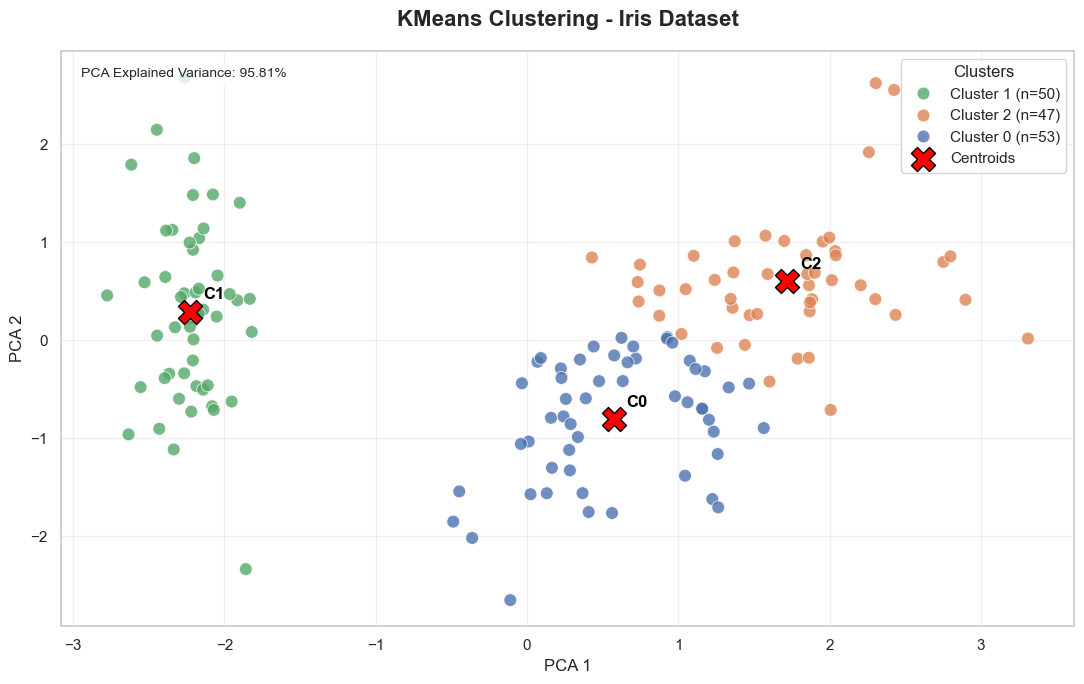


Cluster Counts:
cluster
0    53
1    50
2    47
Name: count, dtype: int64

Final Results:
   sepal.length  sepal.width  petal.length  petal.width variety  cluster  \
0           5.1          3.5           1.4          0.2  Setosa        1   
1           4.9          3.0           1.4          0.2  Setosa        1   
2           4.7          3.2           1.3          0.2  Setosa        1   
3           4.6          3.1           1.5          0.2  Setosa        1   
4           5.0          3.6           1.4          0.2  Setosa        1   
5           5.4          3.9           1.7          0.4  Setosa        1   
6           4.6          3.4           1.4          0.3  Setosa        1   
7           5.0          3.4           1.5          0.2  Setosa        1   
8           4.4          2.9           1.4          0.2  Setosa        1   
9           4.9          3.1           1.5          0.1  Setosa        1   

      PCA 1     PCA 2  Distance to Centroid  
0 -2.264703  0.480027     

In [16]:

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Load Dataset
df = pd.read_csv("data/iris.csv")

# 2. Remove Y (variety)
X = df.drop(columns=["variety"])

# 3. Standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. KMeans
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["cluster"] = kmeans.fit_predict(X_scaled)

# 5. PCA (4D to 2D)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 6. Visualization DataFrame
plot_df = pd.DataFrame({
    "PCA 1": X_pca[:, 0],
    "PCA 2": X_pca[:, 1],
    "cluster": df["cluster"]
})

# Cluster counts
counts = df["cluster"].value_counts().sort_index()

plot_df["Cluster"] = plot_df["cluster"].map(
    lambda x: f"Cluster {x} (n={counts[x]})"
)

# 7. Transform Centroids
centers = pca.transform(kmeans.cluster_centers_)

centers_df = pd.DataFrame({
    "PCA 1": centers[:, 0],
    "PCA 2": centers[:, 1]
})

# 8. Distance to nearest centroid
distances = kmeans.transform(X_scaled).min(axis=1)

# 9. Export CSV
output_df = df.copy()

output_df["PCA 1"] = X_pca[:, 0]
output_df["PCA 2"] = X_pca[:, 1]
output_df["Distance to Centroid"] = distances

os.makedirs("output", exist_ok=True)

output_df.to_csv(
    "output/iris_kmeans_results.csv",
    index=False
)



# 10. Visualization
sns.set_theme(style="whitegrid", context="notebook")

palette = {
    "Cluster 0 (n={})".format(counts[0]): "#4C72B0",
    "Cluster 1 (n={})".format(counts[1]): "#55A868",
    "Cluster 2 (n={})".format(counts[2]): "#DD8452"
}

fig, ax = plt.subplots(figsize=(11, 7))

sns.scatterplot(
    data=plot_df,
    x="PCA 1",
    y="PCA 2",
    hue="Cluster",
    palette=palette,
    s=85,
    alpha=0.8,
    edgecolor="white",
    linewidth=0.6,
    ax=ax
)

# Centroids
sns.scatterplot(
    data=centers_df,
    x="PCA 1",
    y="PCA 2",
    color="red",
    marker="X",
    s=300,
    edgecolor="black",
    linewidth=1,
    label="Centroids",
    ax=ax,
    zorder=5
)

# Centroid labels
for i, center in centers_df.iterrows():
    ax.annotate(
        f"C{i}",
        (center["PCA 1"], center["PCA 2"]),
        xytext=(9, 9),
        textcoords="offset points",
        fontsize=12,
        fontweight="bold",
        color="black"
    )

# Titles and labels
variance = pca.explained_variance_ratio_.sum() * 100

ax.set_title(
    "KMeans Clustering - Iris Dataset",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "PCA 1",
    fontsize=12
)

ax.set_ylabel(
    "PCA 2",
    fontsize=12
)

ax.text(
    0.02,
    0.97,
    f"PCA Explained Variance: {variance:.2f}%",
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        alpha=0.8
    )
)

ax.legend(
    title="Clusters",
    loc="best",
    frameon=True
)

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 11. Cluster Statistics
print("\nCluster Counts:")
print(counts)

print("\nFinal Results:")
print(output_df.head(10))
